# Volatilidad, riesgo y rendimiento ajustado por riesgo

**Autor:** David Niño  
**Área:** Finanzas cuantitativas y análisis de datos  
**Herramientas:** Python, `pandas`, `numpy`, `matplotlib` y `scipy`

## Objetivos de aprendizaje

Al terminar este notebook podrás:

1. Medir la volatilidad como la desviación estándar de los rendimientos.
2. Anualizar la volatilidad con $\sqrt{k}$ y justificar matemáticamente el factor, así como sus límites.
3. Anualizar rendimientos de forma geométrica y relacionar la media aritmética con la geométrica.
4. Calcular el cociente retorno/riesgo, el exceso de rendimiento y la razón de Sharpe.
5. Aplicar todo lo anterior a datos reales: los portafolios por tamaño de empresa de la Biblioteca de Datos de Kenneth French (desde $1926$)

## Referencia de apoyo

Luenberger, D. G. (2014). *Investment science* (2nd ed.). Oxford University Press.

In [1]:
# Instalación (descomentar si hace falta):
# !pip install pandas numpy matplotlib scipy yfinance requests

import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Compatibilidad: pandas >= 2.2 usa "ME" (month end); versiones anteriores usan "M".
FIN_DE_MES = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M"

pd.options.display.float_format = "{:,.6f}".format
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.4.6


## 1. Rendimientos y por qué la media no basta

El rendimiento simple de un período se define como

$$R_t = \frac{P_t}{P_{t-1}} - 1,$$

donde $P_t$ es el precio al final del período $t$. En la teoría media–varianza, el rendimiento de un activo se modela como una **variable aleatoria** $R$; sus dos resúmenes fundamentales son

$$\mu = E[R] \quad \text{(rendimiento esperado)}, \qquad \sigma^2 = E\big[(R-\mu)^2\big] \quad \text{(varianza)}.$$

El rendimiento esperado resume cuánto se espera ganar; la varianza resume cuánto se aleja el resultado de ese valor esperado. Dos activos pueden tener la misma media y comportamientos muy distintos. Esa diferencia es lo que se denomina *volatilidad*.

Para ilustrarlo se usa el siguiente ejemplo:

Rentabilidad media mensual de cada fondo:
Fondo A (Conservador)   0.011667
Fondo B (Agresivo)      0.020000
dtype: float64


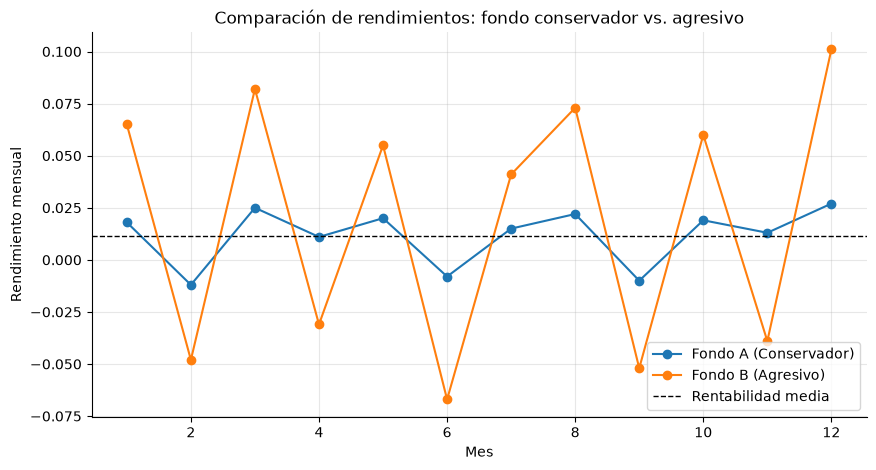

In [2]:
datos_clase = {
    "Fondo A (Conservador)": [
        0.018, -0.012, 0.025, 0.011,0.020, -0.008, 0.015, 0.022, -0.010, 0.019, 0.013, 0.027
    ],
    "Fondo B (Agresivo)": [
        0.065, -0.048, 0.082, -0.031, 0.055, -0.067, 0.041, 0.073, -0.052, 0.060, -0.039, 0.101
    ],
}
rend_demo = pd.DataFrame(
    datos_clase,
    index=pd.RangeIndex(1, 13, name="Mes")
)
print("Rentabilidad media mensual de cada fondo:")
print(rend_demo.mean().round(6))

fig, ax = plt.subplots()
rend_demo.plot(ax=ax, marker="o")
ax.axhline(
    rend_demo["Fondo A (Conservador)"].mean(),
    color="k",
    ls="--",
    lw=1,
    label="Rentabilidad media"
)
ax.set_title(
    "Comparación de rendimientos: fondo conservador vs. agresivo"
)
ax.set_xlabel("Mes")
ax.set_ylabel("Rendimiento mensual")
ax.legend()
plt.show()

Ambas series presentan la misma rentabilidad media mensual, $\bar r = 0.01$ (equivalente al $1\%$). Sin embargo, sus comportamientos son diferentes: mientras que la serie conservadora mantiene sus rendimientos relativamente cerca de la media, la serie agresiva presenta fluctuaciones más pronunciadas y se aleja de ella con mayor magnitud. Esto significa que, aunque ambas inversiones ofrecen la misma rentabilidad promedio, la segunda está expuesta a una mayor volatilidad y, por tanto, a una mayor variabilidad en sus resultados mensuales.

## 2. Volatilidad desde primeros principios

Dada una muestra de $n$ rendimientos $r_1, r_2, \dots, r_n$, el procedimiento consta de cuatro pasos.

**Paso 1. Media muestral.**

$$\bar r = \frac{1}{n}\sum_{t=1}^{n} r_t .$$

**Paso 2. Centrar (*demeaning*).** Se restan la media a cada dato para obtener las desviaciones:

$$d_t = r_t - \bar r .$$

**Paso 3. Elevar al cuadrado y promediar.** Elevar al cuadrado elimina el signo (una desviación de $-3\,\%$ y una de $+3\,\%$ cuentan igual) y penaliza más las desviaciones grandes. El promedio de los cuadrados es la varianza:

$$\sigma^2_{\text{pob}} = \frac{1}{n}\sum_{t=1}^{n}(r_t - \bar r)^2 .$$

**Paso 4. Raíz cuadrada.** La varianza está en unidades de rendimiento al cuadrado, lo que dificulta compararla con los rendimientos. La raíz devuelve la medida a las mismas unidades que los rendimientos:

$$\sigma_{\text{pob}} = \sqrt{\sigma^2_{\text{pob}}} .$$

Esta cantidad es la **volatilidad**. En estadística es, simplemente, la desviación estándar.

In [3]:
n = rend_demo.shape[0]

desviaciones = rend_demo - rend_demo.mean()          # Paso 2
desv_cuadrado = desviaciones ** 2                    # Paso 3 (cuadrados)
varianza_pob = desv_cuadrado.mean()                  # Paso 3 (promedio, divisor n)
vol_pob = np.sqrt(varianza_pob)                      # Paso 4

print("Varianza poblacional:")
print(varianza_pob.round(6))
print("\nVolatilidad poblacional:")
print(vol_pob.round(6))

Varianza poblacional:
Fondo A (Conservador)   0.000176
Fondo B (Agresivo)      0.003497
dtype: float64

Volatilidad poblacional:
Fondo A (Conservador)   0.013269
Fondo B (Agresivo)      0.059135
dtype: float64


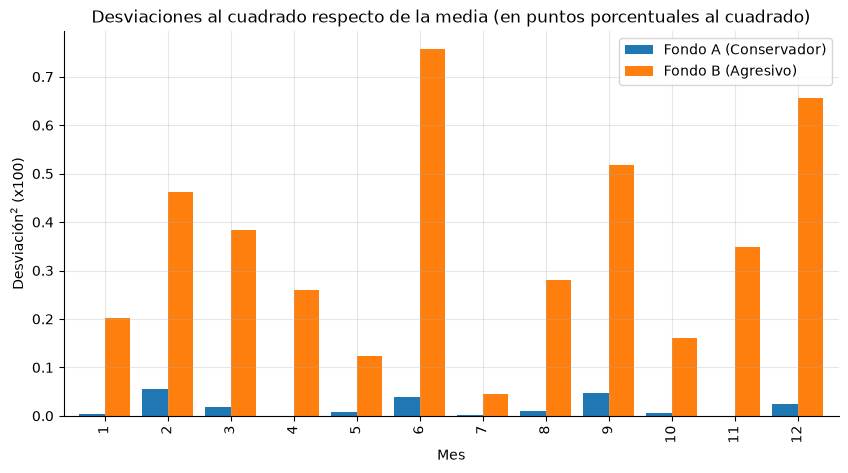

In [4]:
fig, ax = plt.subplots()
(desv_cuadrado * 100).plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Desviaciones al cuadrado respecto de la media (en puntos porcentuales al cuadrado)")
ax.set_xlabel("Mes")
ax.set_ylabel("Desviación$^2$ (x100)")
plt.show()

### 2.1 Varianza poblacional frente a varianza muestral

Si se compara el resultado anterior con el método `.std()` de `pandas`, las cifras no coinciden. La razón es que `.std()` calcula por defecto la desviación estándar muestral, con divisor $n-1$:

$$s^2 = \frac{1}{n-1}\sum_{t=1}^{n}(r_t - \bar r)^2, \qquad s = \sqrt{s^2}.$$

Los rendimientos observados se interpretan como una muestra de una distribución desconocida, cuya media también debe estimarse con los mismos datos. Eso consume un grado de libertad. Con el divisor $n-1$ se obtiene un estimador insesgado de la varianza verdadera:

$$E[s^2] = \sigma^2, \qquad \text{mientras que} \qquad E[\sigma^2_{\text{pob}}] = \frac{n-1}{n}\,\sigma^2 .$$

In [5]:
varianza_mue = desv_cuadrado.sum() / (n - 1)
vol_mue = np.sqrt(varianza_mue)

comparacion = pd.DataFrame({
    "Pob. (divisor n)": vol_pob,
    "Muestral (divisor n-1)": vol_mue,
    ".std() de pandas": rend_demo.std(),
    "np.std(ddof=0)": rend_demo.apply(lambda c: np.std(c, ddof=0)),
})
comparacion

,Pob. (divisor n),Muestral (divisor n-1),.std() de pandas,np.std(ddof=0)
Fondo A (Conservador),0.013269,0.013859,0.013859,0.013269
Fondo B (Agresivo),0.059135,0.061765,0.061765,0.059135


In [6]:
# Verificación numérica
assert np.allclose(vol_mue, rend_demo.std())
assert np.allclose(vol_pob, rend_demo.std(ddof=0))
print("Verificado: .std() usa n-1 por defecto; ddof=0 reproduce la versión poblacional.")

Verificado: .std() usa n-1 por defecto; ddof=0 reproduce la versión poblacional.


## 3. Anualización de la volatilidad

La volatilidad calculada con datos diarios, mensuales o trimestrales no es comparable entre sí: con más datos por año se observan más fluctuaciones intermedias. Para comparar, se lleva todo a una **base anual**.

### 3.1 Justificación matemática

Sea $r_i$ el rendimiento logarítmico del subperíodo $i$, con $r_i = \ln(1+R_i)$. Los rendimientos logarítmicos son aditivos: el rendimiento logarítmico anual es la suma de los $k$ rendimientos de los subperíodos,

$$r_{\text{anual}} = \sum_{i=1}^{k} r_i .$$

Si los $r_i$ son independientes e idénticamente distribuidos con varianza $\sigma^2$, la varianza de la suma es la suma de las varianzas:

$$\operatorname{Var}(r_{\text{anual}}) = k\,\sigma^2 \quad\Longrightarrow\quad \sigma_{\text{anual}} = \sigma\,\sqrt{k}.$$

Por lo tanto,

| Frecuencia de los datos | $k$ | Fórmula |
|---|---|---|
| Mensual | $12$ | $\sigma_{\text{anual}} = \sigma_{\text{mensual}}\sqrt{12}$ |
| Trimestral | $4$ | $\sigma_{\text{anual}} = \sigma_{\text{trimestral}}\sqrt{4}$ |
| Diaria (días de mercado) | $252$ | $\sigma_{\text{anual}} = \sigma_{\text{diaria}}\sqrt{252}$ |

Se usan $252$ y no $365$ porque la volatilidad se genera en los días en que el mercado opera.

**Ejemplo.** Si la volatilidad diaria es $0{,}1\,\%$, entonces
$$\sigma_{\text{anual}} = 0{,}001\times\sqrt{252} \approx 0{,}0159,$$
es decir, aproximadamente $1{,}59\,\%$.

In [7]:
def anualizar_vol(vol_periodica, periodos_por_anio):
    """Anualiza una volatilidad periódica multiplicando por sqrt(k)."""
    return vol_periodica * np.sqrt(periodos_por_anio)

print(f"0,1 % diario  -> {anualizar_vol(0.001, 252):.4%} anual")
print(f"1,0 % diario  -> {anualizar_vol(0.010, 252):.4%} anual")

# Series de ejemplo (mensuales): k = 12
vol_anual_demo = anualizar_vol(rend_demo.std(), 12)
print("\nVolatilidad anualizada:")
print(vol_anual_demo.round(6))

0,1 % diario  -> 1.5875% anual
1,0 % diario  -> 15.8745% anual

Volatilidad anualizada:
Fondo A (Conservador)   0.048008
Fondo B (Agresivo)      0.213960
dtype: float64


## 4. Anualización de rendimientos y rendimiento geométrico

Para comparar rendimientos de series con distinta frecuencia o duración, se calcula el rendimiento anualizado compuesto (geométrico). Con $n$ rendimientos mensuales $R_1,\dots,R_n$:

$$R_{\text{anual}} = \left[\prod_{t=1}^{n}(1+R_t)\right]^{12/n} - 1 .$$

Primero se obtiene el factor de crecimiento total $\prod_t (1+R_t)$; luego se eleva a $12/n$ (para llevarlo a $12$ meses) y se resta uno. Es equivalente a calcular el rendimiento mensual compuesto
$$\bar R_g = \left[\prod_{t=1}^{n}(1+R_t)\right]^{1/n}-1 \quad\text{y luego}\quad R_{\text{anual}} = (1+\bar R_g)^{12}-1 .$$

### 4.1 Media aritmética frente a media geométrica

La media aritmética de los rendimientos sobrestima el crecimiento compuesto cuando hay volatilidad. Para rendimientos logarítmicos con distribución aproximadamente normal, se cumple

$$E[\ln(1+R)] \approx \mu - \frac{\sigma^2}{2},$$

donde $\mu$ y $\sigma^2$ son la media y la varianza del rendimiento simple. El término $\sigma^2/2$ se conoce como *arrastre por volatilidad* (*volatility drag*): a igual media, la serie más volátil crece menos. Esto responde a la pregunta de por qué el mismo promedio no garantiza el mismo resultado final.

In [8]:
def rend_anualizado(r, periodos_por_anio=12):
    """Rendimiento anualizado geométrico a partir de rendimientos periódicos."""
    n = r.shape[0]
    return (1 + r).prod() ** (periodos_por_anio / n) - 1

arrastre = pd.DataFrame({
    "Media aritmética mensual": rend_demo.mean(),
    "Volatilidad mensual (s)": rend_demo.std(),
    "Aproximación: media - s²/2": rend_demo.mean() - rend_demo.std()**2 / 2,
    "Media real de ln(1+R)": np.log1p(rend_demo).mean(),
    "Rend. anualizado geométrico": rend_anualizado(rend_demo),
})
arrastre.T

,Fondo A (Conservador),Fondo B (Agresivo)
Media aritmética mensual,0.011667,0.020000
Volatilidad mensual (s),0.013859,0.061765
Aproximación: media - s²/2,0.011571,0.018093
Media real de ln(1+R),0.011513,0.018104
Rend. anualizado geométrico,0.148148,0.242645


**Interpretación de los resultados**

**Media aritmética mensual**: indica cuánto rentó cada fondo en promedio durante los 12 meses. El Fondo A obtuvo un rendimiento promedio del $1.17\%$, mientras que el Fondo B alcanzó el $2.0\%$. Por tanto, el Fondo B generó una rentabilidad promedio mayor.

**Volatilidad mensual:** mide cuánto varían los rendimientos respecto a su promedio. El Fondo A presenta una volatilidad del $1.39\%$, frente al $6.18\%$ del Fondo B. Esto significa que el Fondo B experimentó mayores fluctuaciones, con meses de ganancias y pérdidas más pronunciadas.

**Aproximación $\mu-s^2/2$ y media real de $\ln(1+R)$**: estos indicadores permiten observar cómo la volatilidad reduce el rendimiento que realmente se acumula en una inversión. La media aritmética del Fondo B es del $2.0\%$ mensual, pero al considerar su volatilidad, el crecimiento logarítmico promedio se reduce aproximadamente al $1.81\%$. Esto ocurre porque las fluctuaciones generan un efecto negativo sobre el crecimiento compuesto. La aproximación $\mu-s^2/2$ ($1.809\%$) es prácticamente igual a la media real de los rendimientos logarítmicos ($1.810\%$), lo que demuestra que la fórmula proporciona una buena estimación para estos datos.

**Rendimiento anualizado geométrico**: indica cuánto habría crecido una inversión durante los 12 meses si se reinvirtieran las ganancias y pérdidas de cada periodo. El Fondo A habría generado un crecimiento acumulado del $14.81\%$, mientras que el Fondo B habría alcanzado el $24.26\%$. Aunque el Fondo B presenta mayor volatilidad, su rentabilidad promedio es suficientemente alta para compensar ese efecto y conseguir un mayor crecimiento acumulado.

## 5. Datos reales I: portafolios formados por tamaño de empresa

Se compara el rendimiento de las empresas más pequeñas de EE. UU. (*small caps*) con el de las más grandes (*large caps*) entre $1926$ y $2018$. Esos datos provienen de la **Biblioteca de Datos de Kenneth French** (Universidad de Dartmouth), que ofrece los rendimientos mensuales de portafolios formados por capitalización de mercado (*ME*, *market equity*): se ordenan las acciones por tamaño y se dividen en deciles; `Lo 10` es el decil de menor tamaño y `Hi 10` el de mayor tamaño. Se usa la versión de ponderación igual (*equal-weighted*).

Además, se descargan los factores mensuales de Fama–French, que incluyen la tasa libre de riesgo `RF` (rendimiento mensual de las letras del Tesoro a un mes).

Los archivos se descargan directamente y se leen con una función auxiliar, porque cada ZIP contiene varias tablas (ponderadas por valor, por igual, anuales, etc.) en un mismo CSV.

In [9]:
URL_FRENCH = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"

def descargar_french(nombre_zip):
    """Descarga un ZIP de la biblioteca de K. French y devuelve el texto del CSV."""
    r = requests.get(URL_FRENCH + nombre_zip, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        return z.read(z.namelist()[0]).decode("latin-1")

def extraer_bloque(texto, titulo=None):
    """
    Extrae una tabla mensual del CSV de French.
    - Si se da `titulo`, busca esa línea y toma la tabla que sigue.
    - Si no, toma la primera tabla del archivo.
    Devuelve un DataFrame en PORCENTAJES con índice mensual (PeriodIndex).
    """
    lineas = texto.splitlines()
    inicio = 0
    if titulo is not None:
        pos = [i for i, l in enumerate(lineas) if titulo.lower() in l.lower()]
        if not pos:
            raise ValueError(f"No se encontró la tabla: {titulo}")
        inicio = pos[0] + 1
    h = next(i for i in range(inicio, len(lineas)) if lineas[i].startswith(","))
    filas = []
    for l in lineas[h + 1:]:
        if not l.strip():
            break
        filas.append(l)
    df = pd.read_csv(io.StringIO("\n".join([lineas[h]] + filas)),
                     index_col=0, na_values=[-99.99, -999])
    df.columns = [c.strip() for c in df.columns]
    df.index = pd.to_datetime(df.index.astype(str).str.strip(), format="%Y%m").to_period("M")
    df.index.name = "Mes"
    return df

try:
    texto_me = descargar_french("Portfolios_Formed_on_ME_CSV.zip")
    me_ew = extraer_bloque(texto_me, "Average Equal Weighted Returns -- Monthly")
    texto_ff = descargar_french("F-F_Research_Data_Factors_CSV.zip")
    ff = extraer_bloque(texto_ff)
except Exception as exc:
    raise RuntimeError(
        "No fue posible descargar los datos de la biblioteca de K. French. "
        "Verifique la conexión a internet o descargue los ZIP manualmente desde "
        "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html"
    ) from exc

print("Portafolios por tamaño (primeras filas, en %):")
display(me_ew.head())
print(f"Rango de fechas: {me_ew.index.min()} a {me_ew.index.max()}  |  observaciones: {len(me_ew)}")

Portafolios por tamaño (primeras filas, en %):


,<= 0,Lo 30,Med 40,Hi 30,Lo 20,Qnt 2,Qnt 3,Qnt 4,Hi 20,Lo 10,2-Dec,3-Dec,4-Dec,5-Dec,6-Dec,7-Dec,8-Dec,9-Dec,Hi 10
Mes,,,,,,,,,,,,,,,,,,,
1926-07,NaN,-0.530000,1.460000,2.630000,-0.680000,0.330000,1.710000,1.480000,3.210000,-1.690000,0.330000,-0.240000,0.900000,1.480000,1.940000,1.510000,1.460000,3.060000,3.340000
1926-08,NaN,3.790000,3.040000,2.120000,3.740000,3.550000,3.680000,1.560000,2.400000,4.930000,2.550000,3.880000,3.220000,2.500000,4.850000,1.570000,1.560000,1.140000,3.580000
1926-09,NaN,-0.930000,-0.480000,0.050000,-0.430000,-1.390000,0.030000,-0.330000,-0.150000,0.860000,-1.720000,-1.940000,-0.840000,0.130000,-0.060000,-1.150000,0.480000,-0.930000,0.580000
1926-10,NaN,-3.390000,-3.570000,-3.110000,-3.250000,-4.340000,-2.960000,-3.400000,-2.940000,-4.730000,-1.770000,-3.670000,-5.010000,-3.200000,-2.710000,-3.370000,-3.440000,-3.760000,-2.190000
1926-11,NaN,-0.340000,3.840000,3.150000,-0.430000,2.320000,3.370000,3.440000,3.190000,-0.530000,-0.330000,-0.170000,4.810000,3.190000,3.540000,3.810000,3.070000,3.800000,2.640000


Rango de fechas: 1926-07 a 2026-09  |  observaciones: 1203


In [10]:
print("Columnas disponibles en me_ew:")
print(me_ew.columns.tolist())

Columnas disponibles en me_ew:
['<= 0', 'Lo 30', 'Med 40', 'Hi 30', 'Lo 20', 'Qnt 2', 'Qnt 3', 'Qnt 4', 'Hi 20', 'Lo 10', '2-Dec', '3-Dec', '4-Dec', '5-Dec', '6-Dec', '7-Dec', '8-Dec', '9-Dec', 'Hi 10']


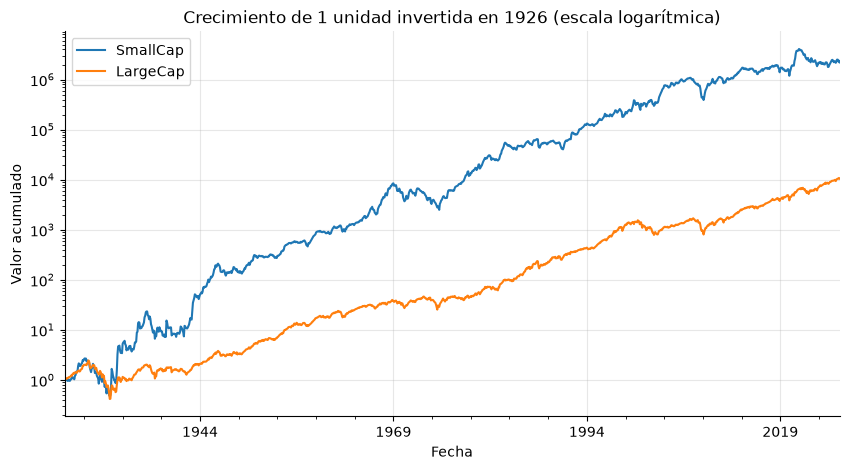

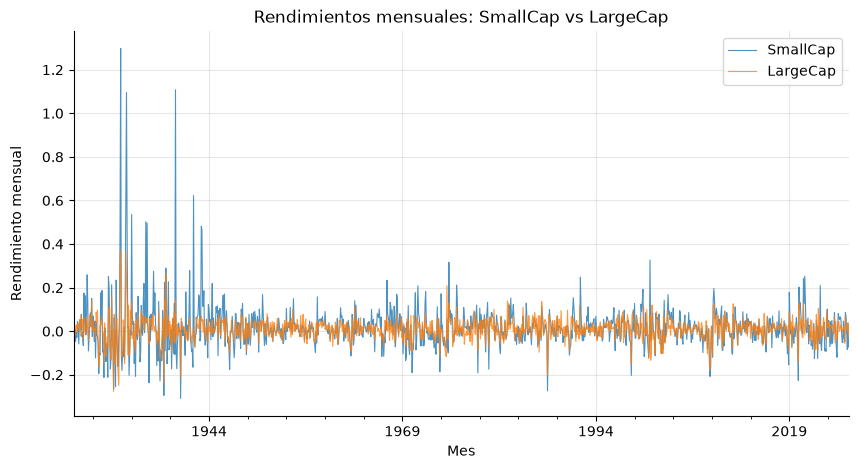

In [11]:
decil_cols = ["Lo 10", "Hi 10"]

# Los datos vienen en porcentaje (4,5 en vez de 0,045): se dividen entre 100
deciles = me_ew[decil_cols].dropna() / 100
rf_mensual = (ff["RF"] / 100).reindex(deciles.index)
mercado = ((ff["Mkt-RF"] + ff["RF"]) / 100).reindex(deciles.index)

rend = deciles[["Lo 10", "Hi 10"]].copy()
rend.columns = ["SmallCap", "LargeCap"]

# Evolución de 1 unidad invertida (escala logarítmica)
riqueza = (1 + rend).cumprod()
fig, ax = plt.subplots()
riqueza.to_timestamp().plot(ax=ax, logy=True)
ax.set_title("Crecimiento de 1 unidad invertida en 1926 (escala logarítmica)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Valor acumulado")
plt.show()

fig, ax = plt.subplots()
rend.to_timestamp().plot(ax=ax, alpha=0.8, lw=0.8)
ax.set_title("Rendimientos mensuales: SmallCap vs LargeCap")
ax.set_ylabel("Rendimiento mensual")
plt.show()


La gráfica de rendimientos muestra con claridad que las empresas pequeñas fluctúan mucho más. A continuación se cuantifica la diferencia. Se define una función que resume rendimiento y riesgo con las fórmulas de las secciones anteriores, y se reproduce el período ($1926$–$2018$).

In [12]:
def resumen_riesgo_retorno(r, rf=0.03, periodos=12):
    """
    Resumen anualizado de rendimiento y riesgo.
    r        : DataFrame de rendimientos periódicos (en decimales)
    rf       : tasa libre de riesgo anual (escalar)
    periodos : períodos por año (12 mensual, 252 diario)
    """
    n = r.shape[0]
    ret_anual = (1 + r).prod() ** (periodos / n) - 1
    vol_anual = r.std() * np.sqrt(periodos)
    out = pd.DataFrame({
        "Rend. anualizado": ret_anual,
        "Vol. anualizada": vol_anual,
        "Retorno / Riesgo": ret_anual / vol_anual,
        "Exceso sobre rf": ret_anual - rf,
        "Sharpe": (ret_anual - rf) / vol_anual,
    })
    return out

rend_clase = rend.loc["1926":"2018"]
print(f"Período: {rend_clase.index.min()} a {rend_clase.index.max()} "
      f"({rend_clase.shape[0]} meses)")

res_clase = resumen_riesgo_retorno(rend_clase, rf=0.03)
res_clase

Período: 1926-07 a 2018-12 (1110 meses)


,Rend. anualizado,Vol. anualizada,Retorno / Riesgo,Exceso sobre rf,Sharpe
SmallCap,0.165302,0.367071,0.450327,0.135302,0.368599
LargeCap,0.093094,0.185104,0.502930,0.063094,0.340858


Con los datos de la clase se obtuvo, para SmallCap, un rendimiento anualizado cercano a $16{,}7\,\%$ y una volatilidad cercana a $36{,}8\,\%$; para LargeCap, aproximadamente $9{,}3\,\%$ y $18{,}7\,\%$. Pueden aparecer pequeñas diferencias respecto de la tabla anterior porque la Biblioteca de French revisa periódicamente sus bases.

## 6. Retorno ajustado por riesgo: razón de Sharpe

### 6.1 Cociente retorno/riesgo

La primera idea para comparar activos con riesgos distintos es medir cuánto rendimiento se obtiene por unidad de volatilidad:

$$\frac{R_{\text{anual}}}{\sigma_{\text{anual}}}.$$

Con los datos de la clase, ese cociente es cercano a $0{,}45$ para SmallCap y a $0{,}50$ para LargeCap, lo que haría parecer que las empresas grandes fueron mejores por unidad de riesgo. Pero este cociente tiene un defecto conceptual.

### 6.2 El exceso de rendimiento y la tasa libre de riesgo

Un inversionista puede obtener un rendimiento sin asumir volatilidad si coloca su dinero en un activo prácticamente libre de riesgo (por ejemplo, letras del Tesoro de EE. UU.), cuya tasa se denota $R_f$. Por lo tanto, solo tiene sentido valorar el rendimiento adicional que compensa el riesgo asumido, el *exceso de rendimiento*:

$$R_{\text{exceso}} = R_{\text{anual}} - R_f .$$

### 6.3 Razón de Sharpe

La **razón de Sharpe** (William Sharpe) es el exceso de rendimiento por unidad de volatilidad:

$$S = \frac{R_{\text{anual}} - R_f}{\sigma_{\text{anual}}} .$$

En el plano riesgo–rendimiento (volatilidad en el eje horizontal, rendimiento en el vertical), $S$ es la pendiente de la recta que une el punto libre de riesgo $(0, R_f)$ con el portafolio $(\sigma, R)$. Esa recta es la que Luenberger denomina línea de asignación de capital (y, para el portafolio de mercado, *línea de mercado de capitales*). Cuanto mayor la pendiente, mejor compensación por riesgo.

A continuación se calcula con la tasa constante $R_f = 3\,\%$ supuesta en la clase.

In [13]:
res_clase[["Retorno / Riesgo", "Sharpe"]].style.format("{:.3f}")

,Retorno / Riesgo,Sharpe
SmallCap,0.450,0.369
LargeCap,0.503,0.341


Una vez descontada la tasa libre de riesgo, **SmallCap** presenta una razón de Sharpe ligeramente mayor que **LargeCap**, a pesar de que su cociente retorno/riesgo simple era menor. La razón es que restar $R_f$ de ambos rendimientos reduce proporcionalmente más al activo de menor rendimiento, y la corrección pesa más sobre **LargeCap**.

### 6.4 Mejora: tasa libre de riesgo observada

Suponer una tasa constante del $3\,\%$ es una simplificación. Con la serie real `RF` (rendimiento mensual de las letras del Tesoro) se calcula el rendimiento anualizado compuesto de la tasa libre de riesgo en el mismo período y se compara.

In [14]:
rf_clase = rf_mensual.loc[rend_clase.index]
rf_anual_real = (1 + rf_clase).prod() ** (12 / len(rf_clase)) - 1
print(f"Tasa libre de riesgo anualizada observada (1926-2018): {rf_anual_real:.2%}  (supuesto de la clase: 3,00 %)")

res_real = resumen_riesgo_retorno(rend_clase, rf=rf_anual_real)

# Variante basada en exceso mensual: S = media(exceso) / desv(exceso) * sqrt(12)
exceso_m = rend_clase.sub(rf_clase, axis=0)
sharpe_mensual = exceso_m.mean() / exceso_m.std() * np.sqrt(12)

tabla_sharpe = pd.DataFrame({
    "Sharpe (rf = 3 % constante)": res_clase["Sharpe"],
    "Sharpe (rf anualizada observada)": res_real["Sharpe"],
    "Sharpe (exceso mensual x sqrt(12))": sharpe_mensual,
})
tabla_sharpe.style.format("{:.3f}")

Tasa libre de riesgo anualizada observada (1926-2018): 3.34%  (supuesto de la clase: 3,00 %)


,Sharpe (rf = 3 % constante),Sharpe (rf anualizada observada),Sharpe (exceso mensual x sqrt(12))
SmallCap,0.369,0.359,0.480
LargeCap,0.341,0.323,0.396


La tabla muestra tres formas de calcular la razón de Sharpe. Las dos primeras usan rendimientos geométricos anualizados; la tercera usa el exceso mensual y la escala por $\sqrt{12}$:

$$S_{\text{mensual}\to\text{anual}} = \frac{\overline{(R_t - R_{f,t})}}{s_{(R_t - R_{f,t})}}\sqrt{12}.$$

Esta última es la definición más habitual en la literatura estadística, pues es coherente con la anualización de la media y de la desviación estándar de una serie de excesos. Se espera que las tres den resultados del mismo orden de magnitud; las diferencias numéricas se deben a usar media geométrica (que incorpora el arrastre por volatilidad) o aritmética, y el estudiante puede verificarlo en la tabla. En esta clase se usa la primera forma para mantener la relación con la grabación.

### 6.5 Los diez deciles de tamaño

La razón de Sharpe permite comparar todos los portafolios formados por tamaño en una sola escala. Se calcula para los $10$ deciles y se ubica cada uno en el plano riesgo–rendimiento, junto con la línea de asignación de capital del decil de mayor Sharpe.

,Rend. anualizado,Vol. anualizada,Retorno / Riesgo,Exceso sobre rf,Sharpe
Lo 10,0.165,0.367,0.450,0.132,0.359
Hi 10,0.093,0.185,0.503,0.060,0.323


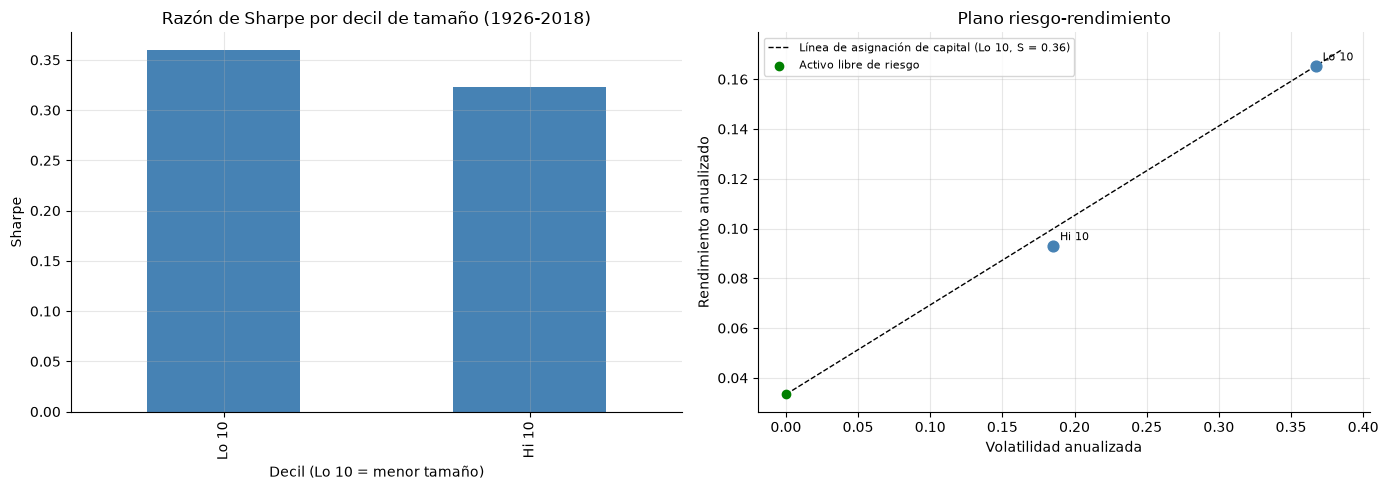

In [15]:
dec_clase = deciles.loc["1926":"2018"]
res_dec = resumen_riesgo_retorno(dec_clase, rf=rf_anual_real)
display(res_dec.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras de Sharpe
res_dec["Sharpe"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Razón de Sharpe por decil de tamaño (1926-2018)")
axes[0].set_xlabel("Decil (Lo 10 = menor tamaño)")
axes[0].set_ylabel("Sharpe")

# Plano riesgo-rendimiento con la línea de asignación de capital
ax = axes[1]
ax.scatter(res_dec["Vol. anualizada"], res_dec["Rend. anualizado"], s=60, color="steelblue", zorder=3)
for nombre, fila in res_dec.iterrows():
    ax.annotate(nombre, (fila["Vol. anualizada"], fila["Rend. anualizado"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
mejor = res_dec["Sharpe"].idxmax()
pend = res_dec.loc[mejor, "Sharpe"]
xs = np.linspace(0, res_dec["Vol. anualizada"].max() * 1.05, 50)
ax.plot(xs, rf_anual_real + pend * xs, "k--", lw=1, label=f"Línea de asignación de capital ({mejor}, S = {pend:.2f})")
ax.scatter([0], [rf_anual_real], color="green", zorder=4, label="Activo libre de riesgo")
ax.set_title("Plano riesgo-rendimiento")
ax.set_xlabel("Volatilidad anualizada")
ax.set_ylabel("Rendimiento anualizado")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. La volatilidad cambia en el tiempo y los rendimientos no son normales

La razón de Sharpe y la anualización con $\sqrt{k}$ suponen, implícitamente, que la volatilidad es un parámetro constante y que la distribución de los rendimientos es bien descrita por su media y su varianza. Conviene contrastar ambos supuestos con los datos.

### 7.1 Volatilidad móvil

Se calcula la desviación estándar de ventanas móviles de $36$ meses, anualizada:

$$\sigma_t^{(36)} = \sqrt{12}\,\sqrt{\frac{1}{35}\sum_{j=0}^{35}\big(r_{t-j}-\bar r_t\big)^2}.$$

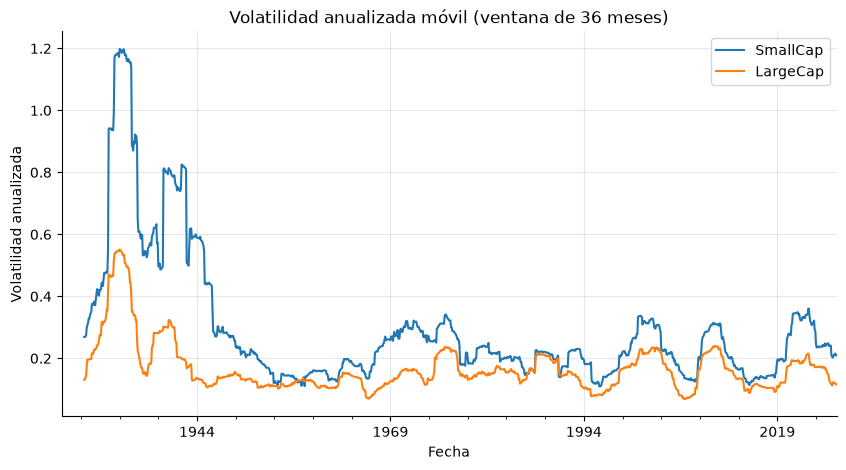

Volatilidad anualizada por década:


,SmallCap,LargeCap
Década,,
1920,29.5%,18.3%
1930,85.9%,36.0%
1940,40.3%,14.7%
1950,15.2%,11.3%
1960,21.8%,12.5%
1970,27.0%,17.3%
1980,20.0%,16.7%
1990,19.2%,13.6%
2000,26.1%,18.7%


Los 5 peores meses de cada serie:

SmallCap


,Rendimiento
Mes,
1940-05,-30.9%
1938-03,-29.5%
1987-10,-27.4%
1931-09,-26.5%
1931-12,-25.4%



LargeCap


,Rendimiento
Mes,
1931-09,-27.6%
1932-05,-25.0%
1938-03,-23.9%
1940-05,-21.0%
1987-10,-20.4%


In [16]:
vol_movil = rend.rolling(36).std() * np.sqrt(12)

fig, ax = plt.subplots()
vol_movil.to_timestamp().plot(ax=ax)
ax.set_title("Volatilidad anualizada móvil (ventana de 36 meses)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Volatilidad anualizada")
plt.show()

# Volatilidad por década
vol_decada = rend.groupby(rend.index.year // 10 * 10).std() * np.sqrt(12)
vol_decada.index.name = "Década"
print("Volatilidad anualizada por década:")
display(vol_decada.style.format("{:.1%}"))

print("Los 5 peores meses de cada serie:")
for col in rend.columns:
    print(f"\n{col}")
    display(rend[col].nsmallest(5).to_frame("Rendimiento").style.format("{:.1%}"))

La volatilidad se concentra en ciertos períodos (por ejemplo, la Gran Depresión de los años $1930$): los períodos de alta volatilidad tienden a agruparse, un fenómeno conocido como *agrupamiento de volatilidad* (*volatility clustering*). Una sola cifra de volatilidad anualizada es, por tanto, un **promedio** sobre regímenes muy distintos.

### 7.2 Forma de la distribución

Dos medidas complementarias a la varianza son:

$$\text{Asimetría} = E\!\left[\left(\frac{R-\mu}{\sigma}\right)^{3}\right], \qquad \text{Curtosis en exceso} = E\!\left[\left(\frac{R-\mu}{\sigma}\right)^{4}\right] - 3 .$$

Para una distribución normal ambas valen $0$. Valores de curtosis en exceso grandes indican colas pesadas: los eventos extremos son más frecuentes de lo que sugiere la desviación estándar.

,Asimetría,Curtosis en exceso,Jarque-Bera (estadístico),Jarque-Bera (p-valor)
SmallCap,4.187,41.324,88373.6,0.00e+00
LargeCap,0.210,7.300,2653.9,0.00e+00


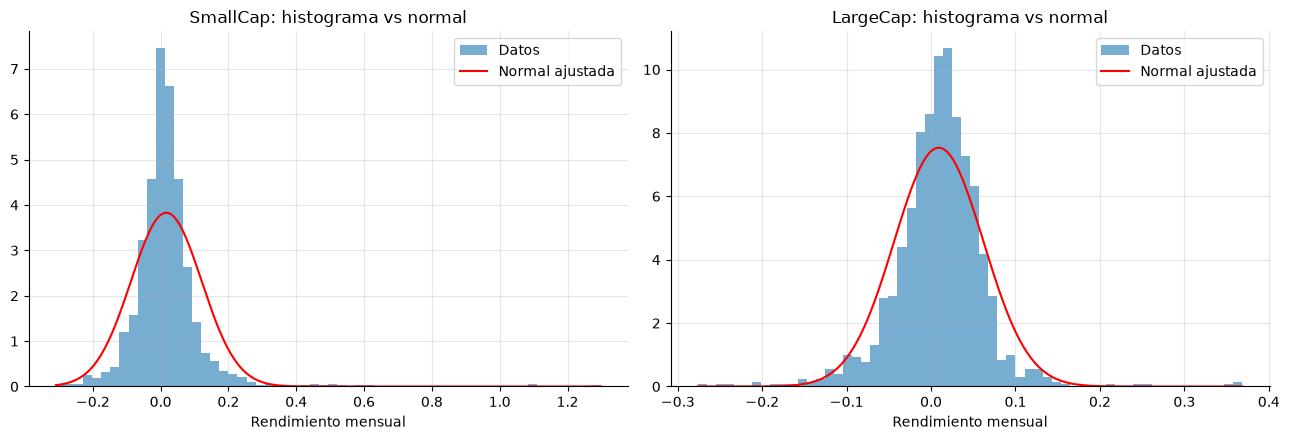

In [17]:
forma = pd.DataFrame({
    "Asimetría": rend.skew(),
    "Curtosis en exceso": rend.kurt(),
    "Jarque-Bera (estadístico)": [stats.jarque_bera(rend[c])[0] for c in rend.columns],
    "Jarque-Bera (p-valor)": [stats.jarque_bera(rend[c])[1] for c in rend.columns],
})
display(forma.style.format({"Asimetría": "{:.3f}", "Curtosis en exceso": "{:.3f}",
                            "Jarque-Bera (estadístico)": "{:.1f}", "Jarque-Bera (p-valor)": "{:.2e}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, rend.columns):
    x = rend[col].dropna()
    ax.hist(x, bins=60, density=True, alpha=0.6, label="Datos")
    grilla = np.linspace(x.min(), x.max(), 300)
    ax.plot(grilla, stats.norm.pdf(grilla, x.mean(), x.std()), "r-", label="Normal ajustada")
    ax.set_title(f"{col}: histograma vs normal")
    ax.set_xlabel("Rendimiento mensual")
    ax.legend()
plt.tight_layout()
plt.show()

El contraste de Jarque–Bera rechaza la normalidad, y la curtosis en exceso es positiva: las colas son más pesadas que las de una normal. **Consecuencia:** la volatilidad (y, por extensión, la razón de Sharpe) no recoge por sí sola el riesgo de pérdidas extremas, por lo que se complementa con otras medidas. La más popular entre los profesionales es el *drawdown*, que se estudia en la siguiente clase.

Volatilidad anualizada ± error estándar analítico:
  SmallCap: 36.71% ± 0.78%
  LargeCap: 18.51% ± 0.39%


,Vol. IC 95 % (inf),Vol. IC 95 % (sup),Sharpe IC 95 % (inf),Sharpe IC 95 % (sup)
SmallCap,0.300,0.438,0.180,0.563
LargeCap,0.169,0.202,0.122,0.571


Diferencia de Sharpe (SmallCap - LargeCap): IC 95 % = [-0.134, 0.184]
Proporción de remuestras con Sharpe(SmallCap) > Sharpe(LargeCap): 63.7%


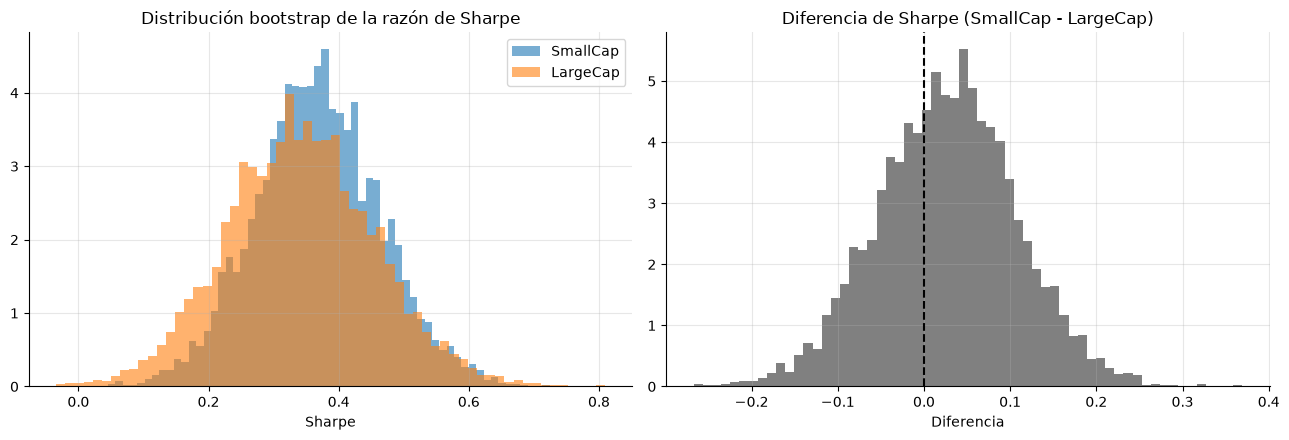

In [18]:
# Error estándar analítico de la volatilidad (aprox., bajo normalidad)
n_cl = rend_clase.shape[0]
ee_vol = rend_clase.std() * np.sqrt(12) / np.sqrt(2 * (n_cl - 1))
print("Volatilidad anualizada ± error estándar analítico:")
for c in rend_clase.columns:
    print(f"  {c}: {rend_clase[c].std()*np.sqrt(12):.2%} ± {ee_vol[c]:.2%}")

# Bootstrap pareado
rng = np.random.default_rng(42)
B = 5000
X = rend_clase.to_numpy()                              # (n, 2)
idx = rng.integers(0, n_cl, size=(B, n_cl))
muestras = X[idx]                                      # (B, n, 2)

ret_b = np.exp(12 / n_cl * np.log1p(muestras).sum(axis=1)) - 1
vol_b = muestras.std(axis=1, ddof=1) * np.sqrt(12)
rf_b = 0.03
sharpe_b = (ret_b - rf_b) / vol_b                      # (B, 2)
dif_b = sharpe_b[:, 0] - sharpe_b[:, 1]                # SmallCap - LargeCap

def ic95(v):
    return np.percentile(v, [2.5, 97.5])

filas = {}
for j, c in enumerate(rend_clase.columns):
    filas[c] = {
        "Vol. IC 95 % (inf)": ic95(vol_b[:, j])[0], "Vol. IC 95 % (sup)": ic95(vol_b[:, j])[1],
        "Sharpe IC 95 % (inf)": ic95(sharpe_b[:, j])[0], "Sharpe IC 95 % (sup)": ic95(sharpe_b[:, j])[1],
    }
display(pd.DataFrame(filas).T.style.format("{:.3f}"))

lo, hi = ic95(dif_b)
print(f"Diferencia de Sharpe (SmallCap - LargeCap): IC 95 % = [{lo:.3f}, {hi:.3f}]")
print(f"Proporción de remuestras con Sharpe(SmallCap) > Sharpe(LargeCap): {(dif_b > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for j, c in enumerate(rend_clase.columns):
    axes[0].hist(sharpe_b[:, j], bins=60, alpha=0.6, label=c, density=True)
axes[0].set_title("Distribución bootstrap de la razón de Sharpe")
axes[0].set_xlabel("Sharpe")
axes[0].legend()
axes[1].hist(dif_b, bins=60, color="gray", density=True)
axes[1].axvline(0, color="k", ls="--")
axes[1].set_title("Diferencia de Sharpe (SmallCap - LargeCap)")
axes[1].set_xlabel("Diferencia")
plt.tight_layout()
plt.show()

**Lectura.** Si el intervalo de confianza de la diferencia contiene al cero, no es posible afirmar con confianza del $95\,\%$ que un activo tuvo mejor razón de Sharpe que el otro, aun cuando las estimaciones puntuales difieran. Esto ilustra por qué la razón de Sharpe debe interpretarse con cautela: es una cantidad estimada, con su propia incertidumbre, incluso con más de $1\,000$ observaciones mensuales.

In [19]:
TICKERS = {
    "ECOPETROL.CL": "Ecopetrol",
    "BCOLOMBIA.CL": "Bancolombia",
    "ISA.CL": "ISA",
    "GRUPOSURA.CL": "Grupo SURA",
    "NUTRESA.CL": "Nutresa",
}
INICIO = "2019-01-01"

def descargar_precios(tickers, inicio):
    import yfinance as yf
    datos = yf.download(list(tickers), start=inicio, auto_adjust=True, progress=False)
    cierre = datos["Close"] if isinstance(datos.columns, pd.MultiIndex) else datos
    return cierre

try:
    precios = descargar_precios(TICKERS, INICIO)
except Exception as exc:
    print("Falló la descarga con yfinance:", exc)
    precios = pd.DataFrame()

# Alternativa: cargar un CSV propio
# precios = pd.read_csv("precios_colombia.csv", index_col="Fecha", parse_dates=True)

# Conservar activos con historia suficiente
precios = precios.rename(columns=TICKERS)
precios = precios.dropna(axis=1, thresh=500).dropna(how="all")
if precios.shape[1] < 2:
    raise RuntimeError("No hay suficientes series de precios. Cargue un CSV propio (ver comentario).")

print("Activos disponibles:", list(precios.columns))
print(f"Rango: {precios.index.min().date()} a {precios.index.max().date()}  |  datos diarios: {len(precios)}")
precios.tail()

Falló la descarga con yfinance: No module named 'yfinance'


RuntimeError: No hay suficientes series de precios. Cargue un CSV propio (ver comentario).

In [ ]:
# Rendimientos diarios y mensuales (precios ajustados -> incluyen dividendos)
ret_d = precios.pct_change(fill_method=None)
precios_m = precios.resample(FIN_DE_MES).last()
ret_m = precios_m.pct_change(fill_method=None).dropna()      # ventana común a todos los activos
ret_d = ret_d.loc[ret_m.index[0] - pd.offsets.MonthEnd(1):]  # misma ventana para los datos diarios

print(f"Ventana común: {ret_m.index[0].date()} a {ret_m.index[-1].date()}  ({len(ret_m)} meses)")

# Evolución de 1.000.000 de COP invertidos al inicio de la ventana
capital = 1_000_000 * (1 + ret_m).cumprod()
fig, ax = plt.subplots()
capital.plot(ax=ax)
ax.set_title("Evolución de COP 1.000.000 invertidos (precios ajustados)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Capital (COP)")
plt.show()

In [ ]:
# 1) Volatilidad anualizada: diaria x sqrt(252) vs mensual x sqrt(12)
vol_diaria_anual = ret_d.std() * np.sqrt(252)
vol_mensual_anual = ret_m.std() * np.sqrt(12)

comp_vol = pd.DataFrame({
    "Desde datos diarios (x sqrt(252))": vol_diaria_anual,
    "Desde datos mensuales (x sqrt(12))": vol_mensual_anual,
})
comp_vol["Diferencia"] = comp_vol.iloc[:, 0] - comp_vol.iloc[:, 1]
display(comp_vol.style.format("{:.2%}"))

Las dos estimaciones son del mismo orden de magnitud, aunque no idénticas: se calculan con distinto número de datos, y la regla $\sqrt{k}$ supone independencia entre rendimientos. En acciones poco líquidas, la falta de negociación diaria produce precios "estancados" que **reducen** la volatilidad diaria observada y generan autocorrelación, lo que explica diferencias sistemáticas.

Ahora se calculan el rendimiento anualizado, la volatilidad y la razón de Sharpe. Para el **activo libre de riesgo** se elige una tasa anual en pesos como **supuesto ilustrativo** (parámetro `RF_COP`). No existe una única tasa correcta: el estudiante debe actualizarla con una referencia vigente (por ejemplo, TES de corto plazo, IBR o la tasa de política del Banco de la República) y justificar su elección. Por eso se acompaña de un análisis de sensibilidad.

In [ ]:
RF_COP = 0.08   # SUPUESTO ILUSTRATIVO: actualizar con una tasa libre de riesgo vigente en COP

res_col = resumen_riesgo_retorno(ret_m, rf=RF_COP, periodos=12)
display(res_col.sort_values("Sharpe", ascending=False).style.format("{:.3f}"))

print("Ranking por rendimiento anualizado :", list(res_col["Rend. anualizado"].sort_values(ascending=False).index))
print("Ranking por razón de Sharpe        :", list(res_col["Sharpe"].sort_values(ascending=False).index))

# Sensibilidad de Sharpe a la tasa libre de riesgo
tasas = [0.04, 0.06, 0.08, 0.10, 0.12]
sens = pd.DataFrame({f"rf = {t:.0%}": resumen_riesgo_retorno(ret_m, rf=t)["Sharpe"] for t in tasas})
print("\nSensibilidad de la razón de Sharpe a la tasa libre de riesgo:")
display(sens.style.format("{:.3f}"))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plano riesgo-rendimiento
ax = axes[0]
ax.scatter(res_col["Vol. anualizada"], res_col["Rend. anualizado"], s=70, zorder=3)
for nombre, fila in res_col.iterrows():
    ax.annotate(nombre, (fila["Vol. anualizada"], fila["Rend. anualizado"]),
                textcoords="offset points", xytext=(6, 4))
ax.scatter([0], [RF_COP], color="green", zorder=4, label=f"Libre de riesgo ({RF_COP:.0%})")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Plano riesgo-rendimiento (acciones colombianas)")
ax.set_xlabel("Volatilidad anualizada")
ax.set_ylabel("Rendimiento anualizado")
ax.legend()

# Volatilidad móvil de 63 días (aprox. un trimestre bursátil)
vol_63 = ret_d.rolling(63).std() * np.sqrt(252)
vol_63.plot(ax=axes[1], lw=1)
axes[1].set_title("Volatilidad anualizada móvil (63 días bursátiles)")
axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Volatilidad anualizada")
plt.tight_layout()
plt.show()

# Correlación entre activos
corr = ret_m.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
ax.set_title("Correlación de rendimientos mensuales")
plt.colorbar(im)
plt.show()

**Observaciones para discusión.**

- La volatilidad móvil suele subir de manera simultánea en todos los activos durante episodios de crisis (por ejemplo, marzo de $2020$): es un indicio de que el riesgo no es constante.
- Un activo con mayor rendimiento no necesariamente tiene mayor razón de Sharpe; el ranking puede cambiar al ajustar por riesgo.
- Un Sharpe **negativo** indica que el activo rindió menos que la tasa libre de riesgo en el período, es decir, el riesgo asumido no fue compensado.
- Las correlaciones menores que $1$ son la base de la diversificación, tema de la siguiente sección.

Correlación mensual SmallCap-LargeCap: 0.676
Verificado: la fórmula de varianza del portafolio coincide con el cálculo directo.

Peso en SmallCap que maximiza el Sharpe: 44%


,Rend,Vol,Sharpe
w_SmallCap,,,
0.000000,0.093,0.185,0.323
0.250000,0.116,0.212,0.392
0.500000,0.136,0.255,0.402
0.440000,0.132,0.244,0.403
1.000000,0.165,0.367,0.359


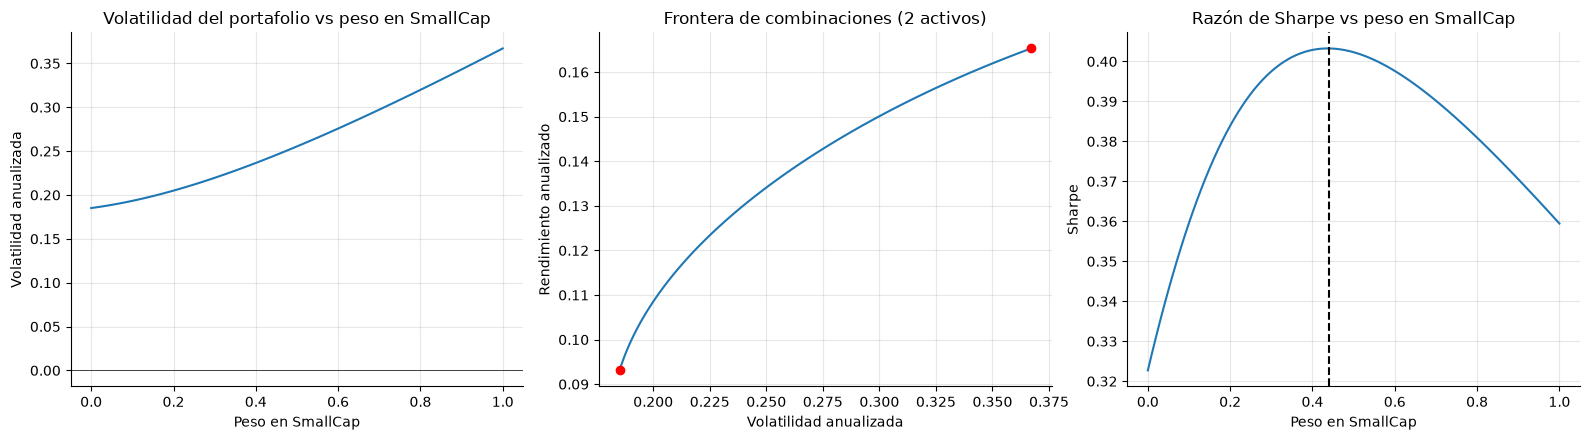

In [20]:
s1, s2 = rend_clase["SmallCap"].std(), rend_clase["LargeCap"].std()
rho = rend_clase["SmallCap"].corr(rend_clase["LargeCap"])
print(f"Correlación mensual SmallCap-LargeCap: {rho:.3f}")

pesos = np.linspace(0, 1, 101)

filas = []
for w in pesos:
    r_p = w * rend_clase["SmallCap"] + (1 - w) * rend_clase["LargeCap"]
    ret = (1 + r_p).prod() ** (12 / len(r_p)) - 1
    vol = r_p.std() * np.sqrt(12)
    vol_formula = np.sqrt(w**2*s1**2 + (1-w)**2*s2**2 + 2*w*(1-w)*rho*s1*s2) * np.sqrt(12)
    filas.append((w, ret, vol, vol_formula, (ret - rf_anual_real) / vol))
cartera = pd.DataFrame(filas, columns=["w_SmallCap", "Rend", "Vol", "Vol_formula", "Sharpe"]).set_index("w_SmallCap")

assert np.allclose(cartera["Vol"], cartera["Vol_formula"])
print("Verificado: la fórmula de varianza del portafolio coincide con el cálculo directo.")

w_opt = cartera["Sharpe"].idxmax()
print(f"\nPeso en SmallCap que maximiza el Sharpe: {w_opt:.0%}")
display(cartera.loc[[0.0, 0.25, 0.5, w_opt, 1.0], ["Rend", "Vol", "Sharpe"]].style.format("{:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cartera["Vol"].plot(ax=axes[0])
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_title("Volatilidad del portafolio vs peso en SmallCap")
axes[0].set_xlabel("Peso en SmallCap"); axes[0].set_ylabel("Volatilidad anualizada")

axes[1].plot(cartera["Vol"], cartera["Rend"])
axes[1].scatter(cartera.loc[[0, 1], "Vol"], cartera.loc[[0, 1], "Rend"], color="red", zorder=3)
axes[1].set_title("Frontera de combinaciones (2 activos)")
axes[1].set_xlabel("Volatilidad anualizada"); axes[1].set_ylabel("Rendimiento anualizado")

cartera["Sharpe"].plot(ax=axes[2])
axes[2].axvline(w_opt, color="k", ls="--")
axes[2].set_title("Razón de Sharpe vs peso en SmallCap")
axes[2].set_xlabel("Peso en SmallCap"); axes[2].set_ylabel("Sharpe")
plt.tight_layout()
plt.show()

La combinación de ambos activos puede lograr una razón de Sharpe superior a la de cualquiera de los dos por separado, siempre que $\rho<1$ y los Sharpe individuales no sean demasiado distintos. Es el germen de la teoría media–varianza de Markowitz que se desarrolla más adelante en el curso (Luenberger, cap. $6$).

## 8. Resumen, limitaciones y ejercicios

### 8.1 Resumen de fórmulas

| Concepto | Fórmula | Interpretación |
|---|---|---|
| Rendimiento simple | $R_t = \dfrac{P_t}{P_{t-1}}-1$ | Cambio porcentual del precio |
| Media muestral | $\bar r = \dfrac{1}{n}\sum_{t=1}^n r_t$ | Rendimiento típico por período |
| Varianza muestral | $s^2 = \dfrac{1}{n-1}\sum_{t=1}^n (r_t-\bar r)^2$ | Promedio de desviaciones al cuadrado (insesgada) |
| Volatilidad | $s=\sqrt{s^2}$ | Desviación estándar de los rendimientos |
| Volatilidad anualizada | $\sigma_{\text{anual}}=s\sqrt{k}$ | $k=12$ (mensual), $k=252$ (diaria) |
| Rendimiento anualizado | $\left[\prod_t (1+R_t)\right]^{12/n}-1$ | Rendimiento compuesto equivalente por año |
| Arrastre por volatilidad | $E[\ln(1+R)]\approx\mu-\sigma^2/2$ | La volatilidad reduce el crecimiento compuesto |
| Retorno/Riesgo | $R_{\text{anual}}/\sigma_{\text{anual}}$ | Rendimiento por unidad de volatilidad |
| Razón de Sharpe | $S=\dfrac{R_{\text{anual}}-R_f}{\sigma_{\text{anual}}}$ | Exceso de rendimiento por unidad de volatilidad |

### 8.2 Limitaciones

1. **Volatilidad no es riesgo completo.** No distingue entre fluctuaciones al alza y a la baja, ni captura pérdidas extremas (colas pesadas).
2. **Anualización con $\sqrt{k}$.** Requiere rendimientos independientes e idénticamente distribuidos; la autocorrelación la invalida (sección $3.2$).
3. **Volatilidad no constante.** Existe agrupamiento de volatilidad (sección $7$).
4. **Sharpe es una estimación.** Tiene incertidumbre estadística considerable (sección $8$), depende de $R_f$ y puede manipularse con estrategias que venden riesgo de cola.
5. **Calidad de datos.** En acciones poco líquidas, los precios desactualizados sesgan la volatilidad a la baja.
6. **Pasado no es futuro.** Los resultados históricos no garantizan resultados futuros.

### Referencias

- Luenberger, D. G. (2014). *Investment science* (2nd ed.). Oxford University Press.
- French, K. R. *Data Library* (Dartmouth College): portafolios formados por tamaño y factores de Fama–French. https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
- Sharpe, W. F. (1994). The Sharpe ratio. *The Journal of Portfolio Management, 21*(1), 49–58.